# 16. Interpretación del modelo final: determinantes del ingreso laboral en el territorio y en el tiempo

**Unidad de análisis:** persona de 18 años o más con ingreso laboral o de negocio trimestral positivo, en cada levantamiento ENIGH 2018, 2020, 2022 y 2024 (cortes transversales repetidos, no un panel). El hogar se usa solo para agrupar errores estándar.

**Pregunta.** ¿Qué factores individuales, educativos, laborales, del hogar y territoriales se asocian con el ingreso laboral en México, cómo difieren entre regiones y tamaños de localidad, y cómo cambiaron entre 2018 y 2024?

**Modelo final.** Es la especificación `M5_final` seleccionada en el notebook 15: forma funcional no lineal (edad cuadrática, *spline* de horas), escolaridad homologada con grados dentro del nivel, variables laborales, del hogar y territoriales, ocupación y sector, y cinco bloques de interacciones que mejoraron el BIC y el ajuste fuera de muestra en los cuatro años. Se estima por separado en cada año sobre $\ln(1+y)$ nominal, con errores agrupados por hogar. Dos complementos:

* `M3_variables_excluidas` (sin ocupación ni sector) para la **asociación total** de la escolaridad, porque ocupación y sector son en parte resultado de la escolaridad (malos controles).
* `M5_entidad` (entidad en lugar de región) para los efectos **estatales**.

Este notebook lee las bases de modelado y las definiciones de especificación exportadas por el notebook 15; **re-estima** todos los modelos y no lee coeficientes previos.

## Cómo leer los resultados

**Por qué no basta con leer las betas.** En un modelo con interacciones, el coeficiente de `sexo_desc[Mujer]` es la brecha **solo** para el perfil de referencia de las variables con que interactúa (40 años, soltera, sin menores, región Centro, localidad urbana grande). Para describir a la población se usa el **efecto promedio contrafactual** (*average marginal effect*, AME) en la escala del modelo:

$$\mathrm{AME}_{\log}(c) = \frac1n\sum_{i=1}^n \big[x_i(c) - x_i(r)\big]'\hat\beta = (\bar x_c - \bar x_r)'\hat\beta,$$

donde $x_i(c)$ es el vector de regresores de la persona $i$ si su variable de interés tomara la categoría $c$, y $x_i(r)$ si tomara la referencia $r$. El resto de sus características se mantiene como se observó. Como es una combinación lineal de $\hat\beta$, su varianza es exacta: $\widehat{\operatorname{Var}} = (\bar x_c - \bar x_r)'\,\hat V_{cl}\,(\bar x_c - \bar x_r)$, con $\hat V_{cl}$ agrupada por hogar.

**Escala.** Se reporta $100[\exp(\mathrm{AME}_{\log}) - 1]$: la diferencia porcentual en $1+$ingreso asociada al cambio, promediada en log sobre la población del año. Es una **asociación condicionada**, no un efecto causal.

**Comparación entre años sin deflactar.** Una diferencia en logaritmos es invariante a un factor de precios común: si todos los ingresos de un año se multiplican por $k$, $\ln(ky_1) - \ln(ky_2) = \ln y_1 - \ln y_2$. Por eso las brechas porcentuales se comparan entre años sin deflactor (con $\ln(1+y)$ la invariancia es aproximada, y la aproximación es muy buena para ingresos alejados de cero). Los **niveles** en pesos nominales sí no son comparables entre años.

**Cambios en el tiempo.** Las muestras de cada año son independientes (hogares distintos), así que la diferencia entre años se contrasta con

$$z = \frac{\widehat{\mathrm{AME}}_{2024} - \widehat{\mathrm{AME}}_{2018}}{\sqrt{\widehat{\operatorname{se}}^2_{2024} + \widehat{\operatorname{se}}^2_{2018}}},$$

y la estabilidad en los cuatro años con $W = \sum_t (\hat a_t - \bar a_w)^2/\hat v_t \sim \chi^2_3$, donde $\bar a_w$ es la media ponderada por precisión. Como se prueban muchos contrastes, los *p-values* se ajustan por Holm (control del error de familia).

# Librerías y configuración

In [1]:
from __future__ import annotations

import json
import sys
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels
import statsmodels.api as sm
from IPython.display import Markdown, display
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import chi2, norm
from statsmodels.stats.multitest import multipletests

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")

ANIOS = [2018, 2020, 2022, 2024]
ANIO_INICIAL, ANIO_FINAL = 2018, 2024
ALFA = 0.05
GRID_EDAD = list(range(18, 81, 2))
GRID_HORAS = list(range(5, 81, 5))
EDAD_REFERENCIA, HORAS_REFERENCIA = 40, 40
EXPORTAR_RESULTADOS = True

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "README.md").exists():
    raise FileNotFoundError("Abrir Jupyter desde la raiz del proyecto o notebooks/.")
MANIFEST_15 = PROJECT_ROOT / "outputs" / "especificacion_validacion_fuera_muestra" / "manifest_especificacion_validacion.json"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "interpretacion_modelo_final"
FIGURAS_REPORTE_DIR = PROJECT_ROOT / "reports" / "figures" / "interpretacion_modelo_final"
KEY_COLS = ["anio", "folioviv", "foliohog", "numren"]
LOG_TARGET = "log1p_ingreso_persona_laboral_negocio_tri"
INICIO_EJECUCION = datetime.now()
z_critico = norm.ppf(1 - ALFA / 2)
COLORES_ANIO = dict(zip(ANIOS, sns.color_palette("viridis", len(ANIOS))))

# Funciones

Las funciones de matriz de diseño reproducen las del notebook 15 (términos numéricos, categóricos, compuestos e interacciones `a:b`, con eliminación registrada de columnas sin variación o linealmente dependientes). `medias_diseno` calcula $\bar x$ para un escenario contrafactual sin eliminar columnas, y la reindexa a las columnas del modelo ajustado.

In [2]:
FIGURAS = {}


def mostrar_figura(fig, nombre):
    FIGURAS[nombre] = fig
    display(fig)
    plt.close(fig)


def pct(x):
    return 100 * (np.exp(x) - 1)


def columnas_termino(datos, termino):
    if ":" in termino:
        izquierda, derecha = termino.split(":", 1)
        a = columnas_termino(datos, izquierda)
        b = columnas_termino(datos, derecha)
        return pd.DataFrame({f"{ca}:{cb}": a[ca].to_numpy() * b[cb].to_numpy() for ca in a for cb in b},
                            index=datos.index)
    if termino in COMPUESTOS:
        return datos[COMPUESTOS[termino]].astype(float)
    if termino in CATEGORIAS:
        serie = datos[termino].astype(str)
        return pd.DataFrame({f"{termino}[{c}]": serie.eq(c).to_numpy(dtype=float)
                             for c in CATEGORIAS[termino] if c != REFERENCIAS[termino]}, index=datos.index)
    if termino in datos:
        return datos[[termino]].astype(float)
    raise KeyError(f"Termino desconocido: {termino}")


def construir_matriz(datos, terminos, tolerancia=1e-7):
    partes = [pd.DataFrame({"const": np.ones(len(datos))}, index=datos.index)]
    for termino in terminos:
        partes.append(columnas_termino(datos, termino))
    X = pd.concat(partes, axis=1)
    X = X.loc[:, ~X.columns.duplicated()]
    X = X.drop(columns=[c for c in X.columns if c != "const" and np.ptp(X[c].to_numpy()) == 0])
    A = X.to_numpy(dtype=float)
    R = np.linalg.qr(A / np.sqrt((A ** 2).sum(axis=0)), mode="r")
    diagonal = np.abs(np.diag(R))
    return X.drop(columns=list(X.columns[diagonal < tolerancia * diagonal.max()]))


def ajustar(datos, terminos):
    X = construir_matriz(datos, terminos)
    ajuste = sm.OLS(datos[LOG_TARGET].astype(float), X).fit(method="qr")
    cluster = ajuste.get_robustcov_results(cov_type="cluster", groups=pd.factorize(datos["id_hogar"])[0],
                                           use_correction=True, use_t=False)
    return {"columnas": list(X.columns), "beta": np.asarray(cluster.params), "V": np.asarray(cluster.cov_params()),
            "r2": ajuste.rsquared, "r2_ajustado": ajuste.rsquared_adj, "aic": ajuste.aic, "bic": ajuste.bic,
            "n": int(ajuste.nobs), "k": int(ajuste.df_model + 1), "terminos": terminos}


def medias_diseno(datos, modelo):
    partes = [pd.DataFrame({"const": np.ones(len(datos))}, index=datos.index)]
    partes += [columnas_termino(datos, t) for t in modelo["terminos"]]
    X = pd.concat(partes, axis=1)
    X = X.loc[:, ~X.columns.duplicated()]
    return X.reindex(columns=modelo["columnas"], fill_value=0.0).mean().to_numpy()


def contrafactual(datos, **cambios):
    c = datos.copy()
    for variable, valor in cambios.items():
        c[variable] = valor
    if "edad" in cambios:
        c["edad_c"] = (c.edad - EDAD_CENTRO) / 10
        c["edad_c2"] = c.edad_c ** 2
    if "horas_acotadas" in cambios:
        c["horas_10"] = c.horas_acotadas / 10
        for nudo in NUDOS_HORAS:
            c[f"horas_s{nudo}"] = (c.horas_acotadas - nudo).clip(lower=0) / 10
    if "region_banxico" in cambios or "tam_loc_grupo" in cambios:
        c["estrato_territorial"] = c.region_banxico + " | " + c.tam_loc_grupo
    return c


def contraste(modelo, media_escenario, media_referencia):
    d = media_escenario - media_referencia
    estimacion = float(d @ modelo["beta"])
    error = float(np.sqrt(d @ modelo["V"] @ d))
    return {"ame_log": estimacion, "error_estandar": error,
            "ame_pct": pct(estimacion), "ic_inferior_pct": pct(estimacion - z_critico * error),
            "ic_superior_pct": pct(estimacion + z_critico * error),
            "p_value": float(2 * norm.sf(abs(estimacion / error))) if error > 0 else np.nan}

## 1. Lectura de las bases de modelado y de la especificación final

Se valida que las bases correspondan a la ejecución completa del notebook 15 (sin submuestra de prueba), con llave única y las columnas requeridas por la especificación.

In [3]:
if not MANIFEST_15.exists():
    raise FileNotFoundError("Ejecutar primero el notebook 15 completo.")
manifest_15 = json.loads(MANIFEST_15.read_text(encoding="utf-8"))
if manifest_15.get("fraccion_hogares_prueba") is not None:
    raise ValueError("El notebook 15 se ejecuto con submuestra de prueba; re-ejecutarlo completo.")
ESPECIFICACIONES = manifest_15["especificaciones"]
REFERENCIAS = manifest_15["referencias"]
CATEGORIAS = manifest_15["categorias"]
COMPUESTOS = manifest_15["compuestos"]
NUDOS_HORAS = manifest_15["nudos_horas"]
EDAD_CENTRO = manifest_15["edad_centro"]
NO_APLICA = "No aplica: sin trabajo principal"
BLOQUES = manifest_15["bloques_seleccionados"]

datos = {}
filas = []
for anio in ANIOS:
    ruta = PROJECT_ROOT / manifest_15["bases_modelo"][str(anio)]
    d = pd.read_csv(ruta, low_memory=False)
    if d.duplicated(KEY_COLS).any() or not d.anio.eq(anio).all():
        raise ValueError(f"{anio}: llave duplicada o año incorrecto.")
    for variable in CATEGORIAS:
        d[variable] = d[variable].astype(str)
    datos[anio] = d
    filas.append({"anio": anio, "personas": len(d), "hogares": d.id_hogar.nunique()})
display(pd.DataFrame(filas))
display(pd.DataFrame([{"especificacion": k, "terminos": " + ".join(v)} for k, v in ESPECIFICACIONES.items()
                      if k in ("M3_variables_excluidas", "M5_final", "M5_entidad")]))
print("Bloques de interaccion en M5:", BLOQUES)

,anio,personas,hogares
0,2018,120054,67807
1,2020,139394,79365
2,2022,141514,80217
3,2024,141578,80871


,especificacion,terminos
0,M3_variables_excluidas,edad_poly + dos_o_mas_trabajos + horas_spline ...
1,M5_final,edad_poly + dos_o_mas_trabajos + horas_spline ...
2,M5_entidad,edad_poly + dos_o_mas_trabajos + horas_spline ...


Bloques de interaccion en M5: ['I1_genero_ciclo_vida', 'I2_educacion_edad', 'I3a_estrato_territorial', 'I3c_genero_territorio', 'I4_laboral']


## 2. Estimación del modelo final por año

Se estiman M5 (principal), M3 (asociación total de la escolaridad) y M5 con entidad, en cada año, con errores agrupados por hogar.

In [4]:
modelos = {}
filas = []
for anio in ANIOS:
    for nombre in ["M5_final", "M3_variables_excluidas", "M5_entidad"]:
        modelos[(anio, nombre)] = ajustar(datos[anio], ESPECIFICACIONES[nombre])
        m = modelos[(anio, nombre)]
        filas.append({"anio": anio, "modelo": nombre, "n": m["n"], "k": m["k"], "r2": m["r2"],
                      "r2_ajustado": m["r2_ajustado"], "aic": m["aic"], "bic": m["bic"]})
ajuste_modelos = pd.DataFrame(filas)
display(ajuste_modelos.pivot(index="modelo", columns="anio", values="r2_ajustado").round(4))

anio,2018,2020,2022,2024
modelo,,,,
M3_variables_excluidas,0.5121,0.4900,0.4926,0.5044
M5_entidad,0.5496,0.5225,0.5322,0.5437
M5_final,0.5454,0.5188,0.5249,0.5369


## 3. Efectos promedio de las variables categóricas y binarias

Para cada variable y categoría se calcula el AME frente a su referencia. Las variables del trabajo principal (subordinación, tamaño de empresa, ocupación, sector, dos o más trabajos) se evalúan solo entre personas **con** trabajo principal, y el contrato solo entre quienes tienen contrato documentado (Sí/No); no se construyen escenarios para las categorías `No aplica`. Las categorías **residuales** de ocupación y sector (trabajo en el extranjero; sector especial o no especificado) permanecen en el modelo como controles, pero no se interpretan: agrupan situaciones muy heterogéneas con pocas observaciones y sus estimaciones son inestables. Para escolaridad, ambos escenarios fijan `grado_relativo = 0`: la comparación es entre niveles **concluidos**. La escolaridad se reporta en M5 (dentro de ocupación y sector) y en M3 (asociación total).

**Inserción laboral.** Subordinación y contrato no pueden cambiarse por separado: el contrato solo existe para personas subordinadas, y los independientes tienen contrato `No aplica`. Cambiar solo la subordinación crearía combinaciones que no ocurren en los datos, como un independiente con contrato o un subordinado sin estatus de contrato. Por eso se define un contraste conjunto entre personas con trabajo principal: **independiente** (referencia) frente a **subordinado sin contrato** y **subordinado con contrato**. El efecto incorpora las interacciones de subordinación con seguridad social y horas.

In [5]:
GRUPOS_VARIABLES = {
    "Individuales": ["sexo_desc", "hablaind_desc", "etnia_grupo", "alfabetismo", "edo_conyugal_grupo", "parentesco_grupo"],
    "Educacion": ["nivel_educativo"],
    "Trabajo": ["contrato_principal_desc", "segsoc_desc", "tam_emp_grupo",
                "sinco_division", "scian_sector"],
    "Hogar": ["est_socio_grupo"],
    "Territorio": ["region_banxico", "tam_loc_grupo"],
}
VARIABLES_TRABAJO = {"subor_principal_desc", "tam_emp_grupo", "sinco_division", "scian_sector"}
CATEGORIAS_RESIDUALES = {"Trabajo en el extranjero", "Especial o no especificado"}
CONTRATO_NO_APLICA = "No aplica: sin contrato principal documentado"
if CONTRATO_NO_APLICA not in CATEGORIAS["contrato_principal_desc"]:
    raise ValueError("Etiqueta estructural de contrato inesperada.")
NOMBRES_VARIABLES = {
    "sexo_desc": "Sexo", "hablaind_desc": "Habla lengua indigena", "etnia_grupo": "Autoadscripcion indigena",
    "alfabetismo": "Alfabetismo", "edo_conyugal_grupo": "Estado conyugal", "parentesco_grupo": "Parentesco",
    "nivel_educativo": "Escolaridad", "subor_principal_desc": "Subordinacion", "contrato_principal_desc": "Contrato",
    "segsoc_desc": "Seguridad social", "tam_emp_grupo": "Tamano de empresa", "sinco_division": "Ocupacion",
    "scian_sector": "Sector", "est_socio_grupo": "Estrato socioeconomico", "region_banxico": "Region",
    "tam_loc_grupo": "Tamano de localidad", "dos_o_mas_trabajos": "Dos o mas trabajos",
    "grado_relativo": "Grado adicional dentro del nivel", "insercion_laboral": "Insercion laboral", "menores": "Un menor mas en el hogar",
    "tot_integ": "Un integrante mas en el hogar", "p65mas": "Una persona de 65+ mas en el hogar",
}


def universo(d, variable):
    if variable in VARIABLES_TRABAJO or variable == "dos_o_mas_trabajos":
        return d.loc[d.subor_grupo.ne(NO_APLICA)]
    if variable == "contrato_principal_desc":
        return d.loc[d.contrato_principal_desc.isin(["Sí", "No"])]
    return d


filas = []
for anio in ANIOS:
    for nombre_modelo in ["M5_final", "M3_variables_excluidas"]:
        modelo = modelos[(anio, nombre_modelo)]
        variables = [v for g in GRUPOS_VARIABLES.values() for v in g]
        if nombre_modelo == "M3_variables_excluidas":
            variables = ["nivel_educativo"]
        for variable in variables:
            base = universo(datos[anio], variable)
            fijos = {"grado_relativo": 0.0} if variable == "nivel_educativo" else {}
            referencia = REFERENCIAS[variable]
            media_ref = medias_diseno(contrafactual(base, **{variable: referencia}, **fijos), modelo)
            for categoria in CATEGORIAS[variable]:
                if categoria == referencia or categoria.startswith("No aplica") or categoria in CATEGORIAS_RESIDUALES:
                    continue
                media = medias_diseno(contrafactual(base, **{variable: categoria}, **fijos), modelo)
                filas.append({"anio": anio, "modelo": nombre_modelo, "variable": variable, "categoria": categoria,
                              "referencia": referencia, "n_universo": len(base), **contraste(modelo, media, media_ref)})
        if nombre_modelo == "M5_final":
            base = universo(datos[anio], "subor_principal_desc")
            media_ref = medias_diseno(contrafactual(base, subor_principal_desc="No",
                                                    contrato_principal_desc=CONTRATO_NO_APLICA), modelo)
            for categoria, contrato in [("Subordinado sin contrato", "No"), ("Subordinado con contrato", "Sí")]:
                media = medias_diseno(contrafactual(base, subor_principal_desc="Sí", contrato_principal_desc=contrato), modelo)
                filas.append({"anio": anio, "modelo": nombre_modelo, "variable": "insercion_laboral",
                              "categoria": categoria, "referencia": "Independiente", "n_universo": len(base),
                              **contraste(modelo, media, media_ref)})
            base = universo(datos[anio], "dos_o_mas_trabajos")
            filas.append({"anio": anio, "modelo": nombre_modelo, "variable": "dos_o_mas_trabajos", "categoria": "Si",
                          "referencia": "Un trabajo", "n_universo": len(base),
                          **contraste(modelo, medias_diseno(contrafactual(base, dos_o_mas_trabajos=1.0), modelo),
                                      medias_diseno(contrafactual(base, dos_o_mas_trabajos=0.0), modelo))})
            for variable in ["grado_relativo", "menores", "tot_integ", "p65mas"]:
                base = datos[anio]
                filas.append({"anio": anio, "modelo": nombre_modelo, "variable": variable, "categoria": "+1",
                              "referencia": "valor observado", "n_universo": len(base),
                              **contraste(modelo, medias_diseno(contrafactual(base, **{variable: base[variable] + 1}), modelo),
                                          medias_diseno(base, modelo))})
efectos_promedio = pd.DataFrame(filas)
efectos_promedio["etiqueta"] = (efectos_promedio.variable.map(NOMBRES_VARIABLES) + ": "
                                + efectos_promedio.categoria + " vs " + efectos_promedio.referencia)
display(efectos_promedio.loc[efectos_promedio.modelo.eq("M5_final")]
        .pivot_table(index="etiqueta", columns="anio", values="ame_pct", sort=False).round(1))

anio,2018,2020,2022,2024
etiqueta,,,,
Sexo: Mujer vs Hombre,-31.1,-28.9,-29.1,-28.0
Habla lengua indigena: Sí vs No,-14.2,-19.3,-14.1,-16.5
Autoadscripcion indigena: Si vs No,-4.2,-3.5,-4.1,-4.9
Alfabetismo: No vs Sí,-12.8,-14.6,-16.1,-18.5
Estado conyugal: Casado(a) vs Soltero(a),6.8,7.7,7.3,5.6
...,...,...,...,...
Dos o mas trabajos: Si vs Un trabajo,1.8,-1.1,3.5,4.2
Grado adicional dentro del nivel: +1 vs valor observado,2.9,2.4,2.6,2.7
Un menor mas en el hogar: +1 vs valor observado,-1.0,0.0,-0.9,-1.5


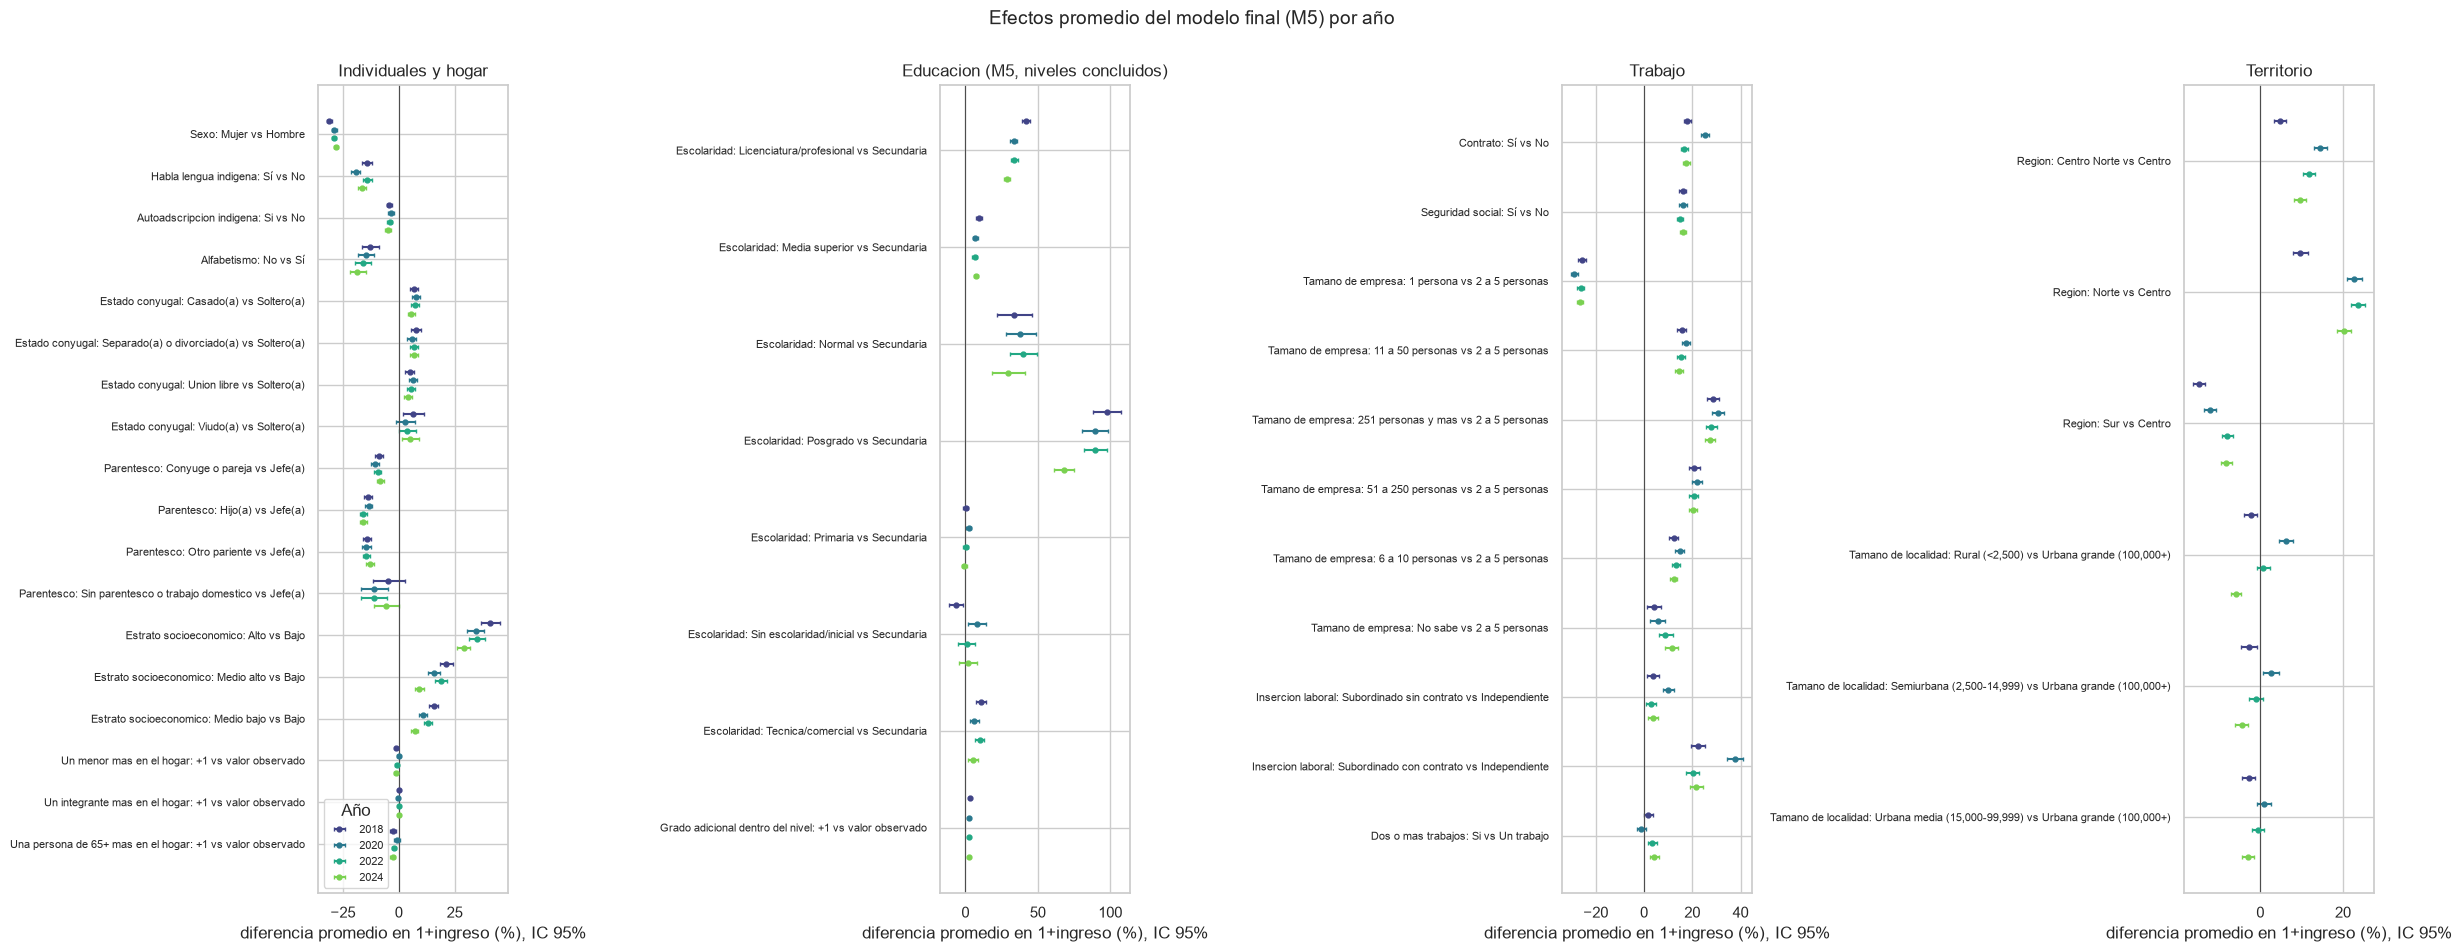

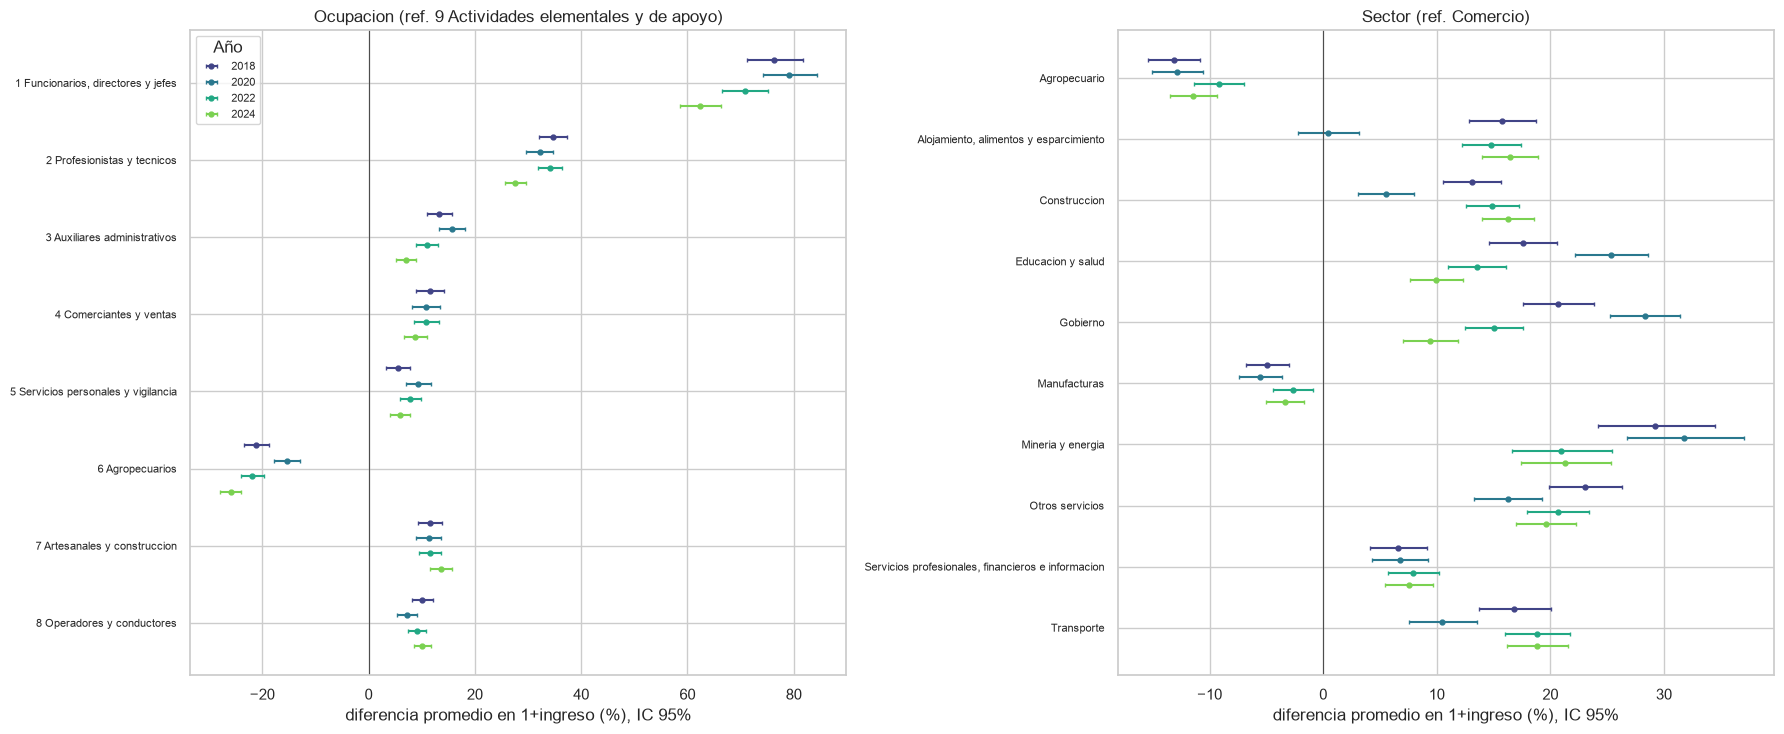

In [6]:
def forest(ax, tabla, columna_etiqueta="etiqueta", anios=ANIOS, titulo=""):
    etiquetas = list(dict.fromkeys(tabla[columna_etiqueta]))
    desplazamientos = dict(zip(anios, np.linspace(-0.3, 0.3, len(anios))))
    for anio in anios:
        sub = tabla.loc[tabla.anio.eq(anio)].set_index(columna_etiqueta).reindex(etiquetas)
        ax.errorbar(sub.ame_pct, np.arange(len(etiquetas)) + desplazamientos[anio],
                    xerr=[sub.ame_pct - sub.ic_inferior_pct, sub.ic_superior_pct - sub.ame_pct],
                    fmt="o", ms=3.5, capsize=1.5, color=COLORES_ANIO[anio], label=str(anio))
    ax.axvline(0, color="0.3", linewidth=0.8)
    ax.set_yticks(range(len(etiquetas)), etiquetas, fontsize=8)
    ax.invert_yaxis()
    ax.set_title(titulo)
    ax.set_xlabel("diferencia promedio en 1+ingreso (%), IC 95%")


m5 = efectos_promedio.loc[efectos_promedio.modelo.eq("M5_final")].copy()
m5["etiqueta_corta"] = m5.categoria + " vs " + m5.referencia
paneles = [("Individuales y hogar", ["sexo_desc", "hablaind_desc", "etnia_grupo", "alfabetismo", "edo_conyugal_grupo",
                                     "parentesco_grupo", "est_socio_grupo", "menores", "tot_integ", "p65mas"]),
           ("Educacion (M5, niveles concluidos)", ["nivel_educativo", "grado_relativo"]),
           ("Trabajo", ["insercion_laboral", "contrato_principal_desc", "segsoc_desc", "dos_o_mas_trabajos", "tam_emp_grupo"]),
           ("Territorio", ["region_banxico", "tam_loc_grupo"])]
fig, ejes = plt.subplots(1, 4, figsize=(24, 9.5))
for ax, (titulo, variables) in zip(ejes, paneles):
    sub = m5.loc[m5.variable.isin(variables)].copy()
    sub["etiqueta"] = sub.variable.map(NOMBRES_VARIABLES) + ": " + sub.etiqueta_corta
    forest(ax, sub, titulo=titulo)
ejes[0].legend(title="Año", loc="lower left", fontsize=8)
fig.suptitle("Efectos promedio del modelo final (M5) por año", y=1.0, fontsize=14)
fig.tight_layout()
mostrar_figura(fig, "panorama_efectos_promedio")

fig, ejes = plt.subplots(1, 2, figsize=(18, 7.5))
for ax, variable in zip(ejes, ["sinco_division", "scian_sector"]):
    sub = m5.loc[m5.variable.eq(variable)].copy()
    sub["etiqueta"] = sub.categoria
    forest(ax, sub, titulo=f"{NOMBRES_VARIABLES[variable]} (ref. {REFERENCIAS[variable]})")
ejes[0].legend(title="Año", fontsize=8)
fig.tight_layout()
mostrar_figura(fig, "ocupacion_sector")

## 4. Escolaridad: asociación total y dentro de la ocupación

La prima de cada nivel concluido frente a Secundaria concluida se compara entre M3 (sin ocupación ni sector: asociación total) y M5 (dentro de ocupación y sector). La distancia entre ambas aproxima cuánto de la asociación educativa opera **a través** del tipo de ocupación y sector al que se accede. Además, el bloque educación × edad permite que la prima cambie a lo largo del ciclo de vida.

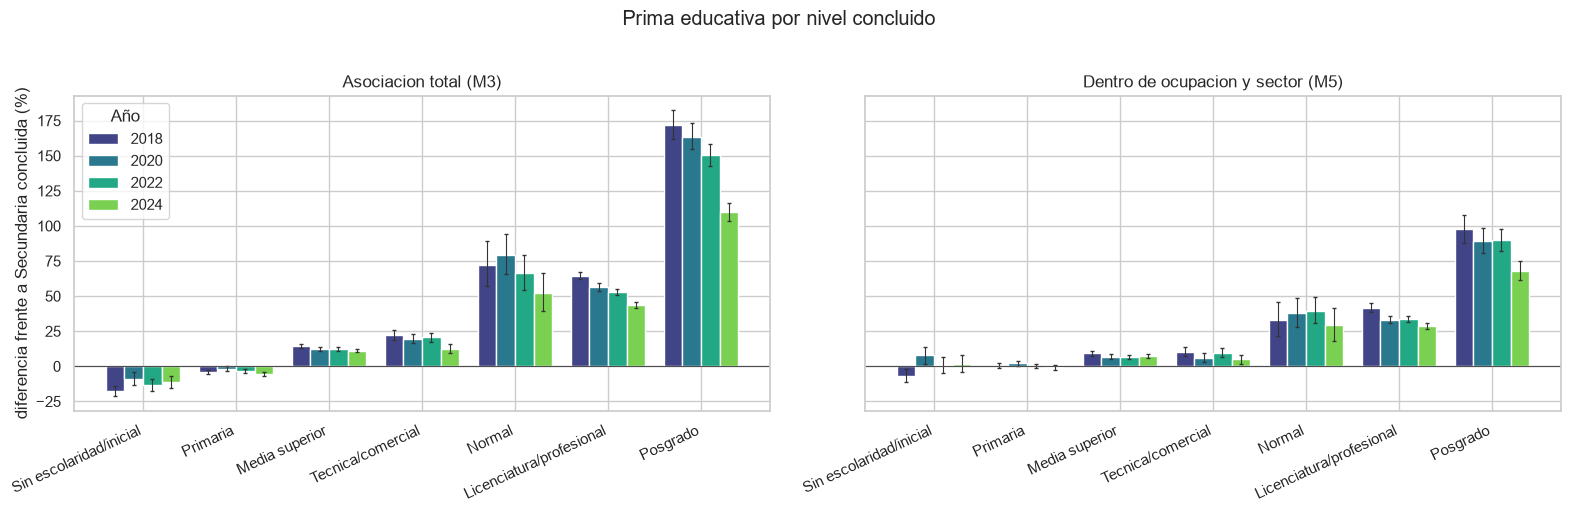

modelo                   M3_variables_excluidas                      M5_final                  
anio                                       2018   2020   2022   2024     2018  2020  2022  2024
categoria                                                                                      
Licenciatura/profesional                   64.7   56.5   52.7   43.4     41.8  33.2  33.8  28.9
Media superior                             14.4   12.5   12.0   11.2      9.2   6.8   6.5   7.2
Normal                                     72.3   79.5   66.2   52.2     33.3  37.9  39.5  29.3
Posgrado                                  171.9  163.7  150.3  110.0     97.7  89.3  89.6  68.0
Primaria                                   -4.1   -1.7   -3.5   -5.3      0.3   2.2   0.1  -0.7
Sin escolaridad/inicial                   -17.7   -8.8  -13.3  -11.5     -6.7   7.7   0.9   1.6
Tecnica/comercial                          22.2   19.8   20.6   12.6     10.5   6.3   9.8   5.1

In [7]:
educacion = efectos_promedio.loc[efectos_promedio.variable.eq("nivel_educativo")].copy()
orden_niveles = ["Sin escolaridad/inicial", "Primaria", "Media superior", "Tecnica/comercial", "Normal",
                 "Licenciatura/profesional", "Posgrado"]
fig, ejes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, (modelo, titulo) in zip(ejes, [("M3_variables_excluidas", "Asociacion total (M3)"),
                                       ("M5_final", "Dentro de ocupacion y sector (M5)")]):
    sub = educacion.loc[educacion.modelo.eq(modelo)]
    ancho = 0.2
    for j, anio in enumerate(ANIOS):
        s = sub.loc[sub.anio.eq(anio)].set_index("categoria").reindex(orden_niveles)
        posiciones = np.arange(len(orden_niveles)) + (j - 1.5) * ancho
        ax.bar(posiciones, s.ame_pct, width=ancho, color=COLORES_ANIO[anio], label=str(anio))
        ax.errorbar(posiciones, s.ame_pct, yerr=[s.ame_pct - s.ic_inferior_pct, s.ic_superior_pct - s.ame_pct],
                    fmt="none", color="0.2", capsize=1.5, linewidth=0.8)
    ax.axhline(0, color="0.3", linewidth=0.8)
    ax.set_xticks(range(len(orden_niveles)), orden_niveles, rotation=25, ha="right")
    ax.set_title(titulo)
ejes[0].set_ylabel("diferencia frente a Secundaria concluida (%)")
ejes[0].legend(title="Año")
fig.suptitle("Prima educativa por nivel concluido", y=1.02)
fig.tight_layout()
mostrar_figura(fig, "prima_educativa_m3_m5")
display(educacion.pivot_table(index=["categoria"], columns=["modelo", "anio"], values="ame_pct").round(1))

## 5. Ciclo de vida: perfiles de edad por sexo y por escolaridad

Se fija la edad de **todas** las personas en cada valor de la rejilla (y, en su caso, el sexo o el nivel educativo), y se promedian las predicciones. El resultado se expresa frente al perfil de referencia de cada año: hombres de 40 años, o Secundaria a los 40 años en el perfil educativo. Así se lee la forma del perfil y la brecha entre grupos, no el nivel absoluto, que es nominal.

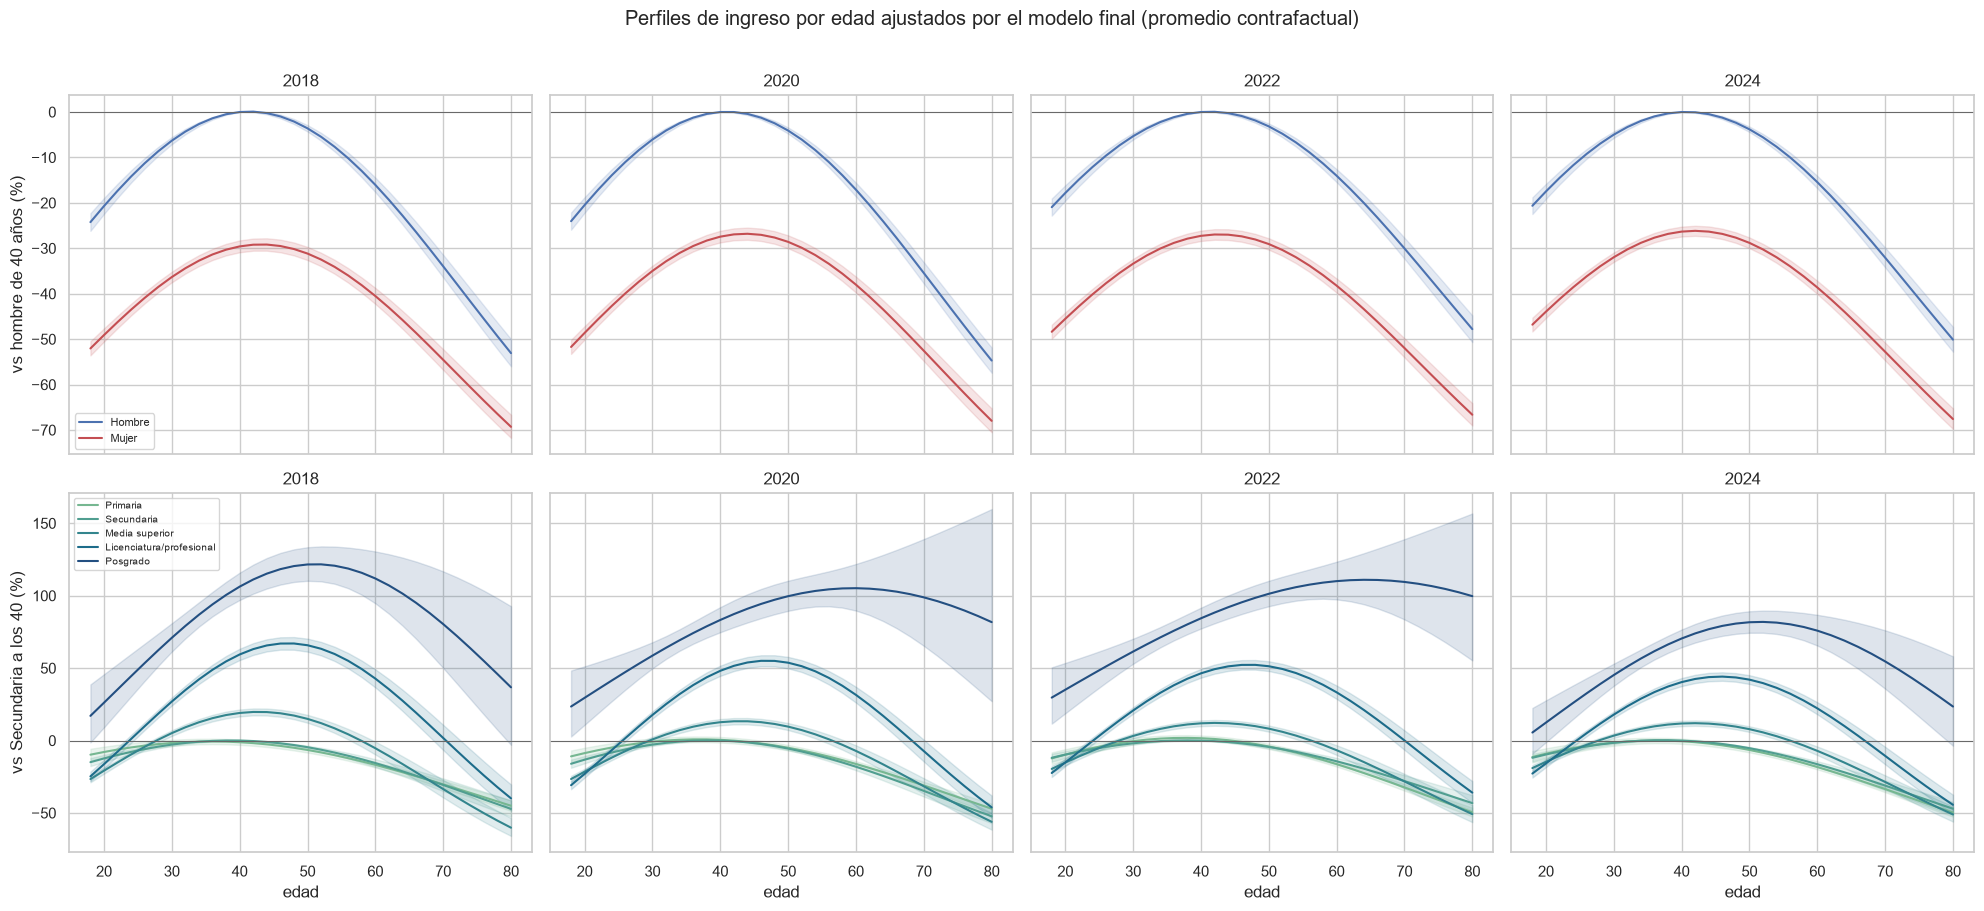

,anio,grupo,edad_maximo,nivel_en_maximo_pct
84,2018,Hombre,42,0.082136
301,2020,Hombre,40,0.000000
532,2022,Hombre,42,0.051987
749,2024,Hombre,40,0.000000
92,2018,Mujer,44,-29.176073
316,2020,Mujer,44,-26.801194
533,2022,Mujer,42,-26.963359
757,2024,Mujer,42,-26.156626


In [8]:
filas = []
for anio in ANIOS:
    modelo, d = modelos[(anio, "M5_final")], datos[anio]
    ref_sexo = medias_diseno(contrafactual(d, edad=EDAD_REFERENCIA, sexo_desc="Hombre"), modelo)
    ref_edu = medias_diseno(contrafactual(d, edad=EDAD_REFERENCIA, nivel_educativo="Secundaria", grado_relativo=0.0), modelo)
    for edad in GRID_EDAD:
        for sexo in ["Hombre", "Mujer"]:
            filas.append({"anio": anio, "perfil": "sexo", "grupo": sexo, "edad": edad,
                          **contraste(modelo, medias_diseno(contrafactual(d, edad=edad, sexo_desc=sexo), modelo), ref_sexo)})
        for nivel in ["Primaria", "Secundaria", "Media superior", "Licenciatura/profesional", "Posgrado"]:
            filas.append({"anio": anio, "perfil": "escolaridad", "grupo": nivel, "edad": edad,
                          **contraste(modelo, medias_diseno(contrafactual(d, edad=edad, nivel_educativo=nivel,
                                                                          grado_relativo=0.0), modelo), ref_edu)})
perfiles_edad = pd.DataFrame(filas)

fig, ejes = plt.subplots(2, len(ANIOS), figsize=(20, 9), sharex=True, sharey="row")
colores_sexo = {"Hombre": "#4c72b0", "Mujer": "#c44e52"}
colores_edu = dict(zip(["Primaria", "Secundaria", "Media superior", "Licenciatura/profesional", "Posgrado"],
                       sns.color_palette("crest", 5)))
for j, anio in enumerate(ANIOS):
    for fila_ax, perfil, colores in [(0, "sexo", colores_sexo), (1, "escolaridad", colores_edu)]:
        ax = ejes[fila_ax, j]
        sub = perfiles_edad.loc[perfiles_edad.anio.eq(anio) & perfiles_edad.perfil.eq(perfil)]
        for grupo, color in colores.items():
            s = sub.loc[sub.grupo.eq(grupo)]
            ax.plot(s.edad, s.ame_pct, color=color, label=grupo)
            ax.fill_between(s.edad, s.ic_inferior_pct, s.ic_superior_pct, color=color, alpha=0.15)
        ax.axhline(0, color="0.4", linewidth=0.7)
        ax.set_title(f"{anio}")
        if j == 0:
            ax.set_ylabel("vs hombre de 40 años (%)" if perfil == "sexo" else "vs Secundaria a los 40 (%)")
    ejes[1, j].set_xlabel("edad")
ejes[0, 0].legend(fontsize=8)
ejes[1, 0].legend(fontsize=7)
fig.suptitle("Perfiles de ingreso por edad ajustados por el modelo final (promedio contrafactual)", y=1.01)
fig.tight_layout()
mostrar_figura(fig, "perfiles_edad")

pico = (perfiles_edad.loc[perfiles_edad.perfil.eq("sexo")].sort_values("ame_log")
        .groupby(["anio", "grupo"]).tail(1)[["anio", "grupo", "edad", "ame_pct"]]
        .rename(columns={"edad": "edad_maximo", "ame_pct": "nivel_en_maximo_pct"}))
display(pico.sort_values(["grupo", "anio"]))

## 6. Horas trabajadas por tipo de inserción laboral

El *spline* de horas interactúa con la subordinación. Se fija el número de horas de cada persona con trabajo principal en una rejilla, **dentro de su propio grupo** (subordinados o independientes), y se compara contra 40 horas.

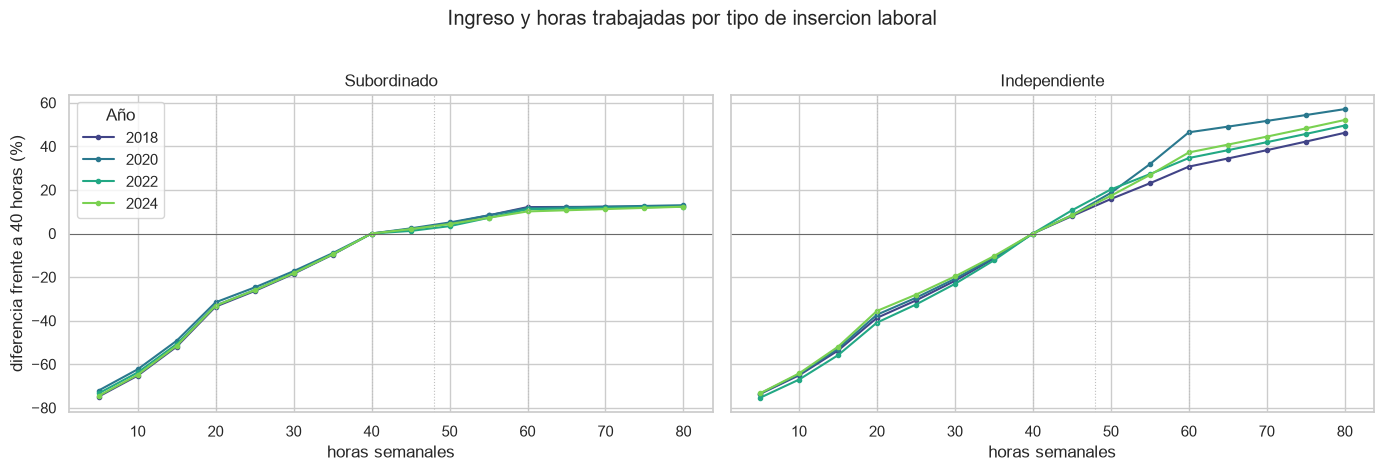

In [9]:
filas = []
for anio in ANIOS:
    modelo = modelos[(anio, "M5_final")]
    for grupo in ["Subordinado", "Independiente"]:
        d = datos[anio].loc[datos[anio].subor_grupo.eq(grupo)]
        referencia = medias_diseno(contrafactual(d, horas_acotadas=float(HORAS_REFERENCIA)), modelo)
        for horas in GRID_HORAS:
            filas.append({"anio": anio, "grupo": grupo, "horas": horas,
                          **contraste(modelo, medias_diseno(contrafactual(d, horas_acotadas=float(horas)), modelo), referencia)})
perfiles_horas = pd.DataFrame(filas)
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, grupo in zip(ejes, ["Subordinado", "Independiente"]):
    for anio in ANIOS:
        s = perfiles_horas.loc[perfiles_horas.anio.eq(anio) & perfiles_horas.grupo.eq(grupo)]
        ax.plot(s.horas, s.ame_pct, marker="o", ms=3, color=COLORES_ANIO[anio], label=str(anio))
    for nudo in NUDOS_HORAS:
        ax.axvline(nudo, color="0.75", linestyle=":", linewidth=0.8)
    ax.axhline(0, color="0.4", linewidth=0.7)
    ax.set(title=grupo, xlabel="horas semanales")
ejes[0].set_ylabel("diferencia frente a 40 horas (%)")
ejes[0].legend(title="Año")
fig.suptitle("Ingreso y horas trabajadas por tipo de insercion laboral", y=1.02)
fig.tight_layout()
mostrar_figura(fig, "perfil_horas")

## 7. Territorio: estratos, brecha de género y entidades

* **Estrato territorial:** se asigna a todas las personas cada combinación región × tamaño de localidad y se compara con Centro | urbana grande. Combina los efectos principales y la interacción región × localidad.
* **Brecha de género por territorio:** diferencia Mujer frente a Hombre dentro de cada celda territorial, gracias a las interacciones sexo × región y sexo × localidad.
* **Entidades:** en `M5_entidad`, la entidad entra solo como efecto principal, así que su coeficiente ya es el efecto promedio frente a Ciudad de México. Se aplica la misma contracción bayesiana empírica del notebook 15 para separar señal de ruido muestral.

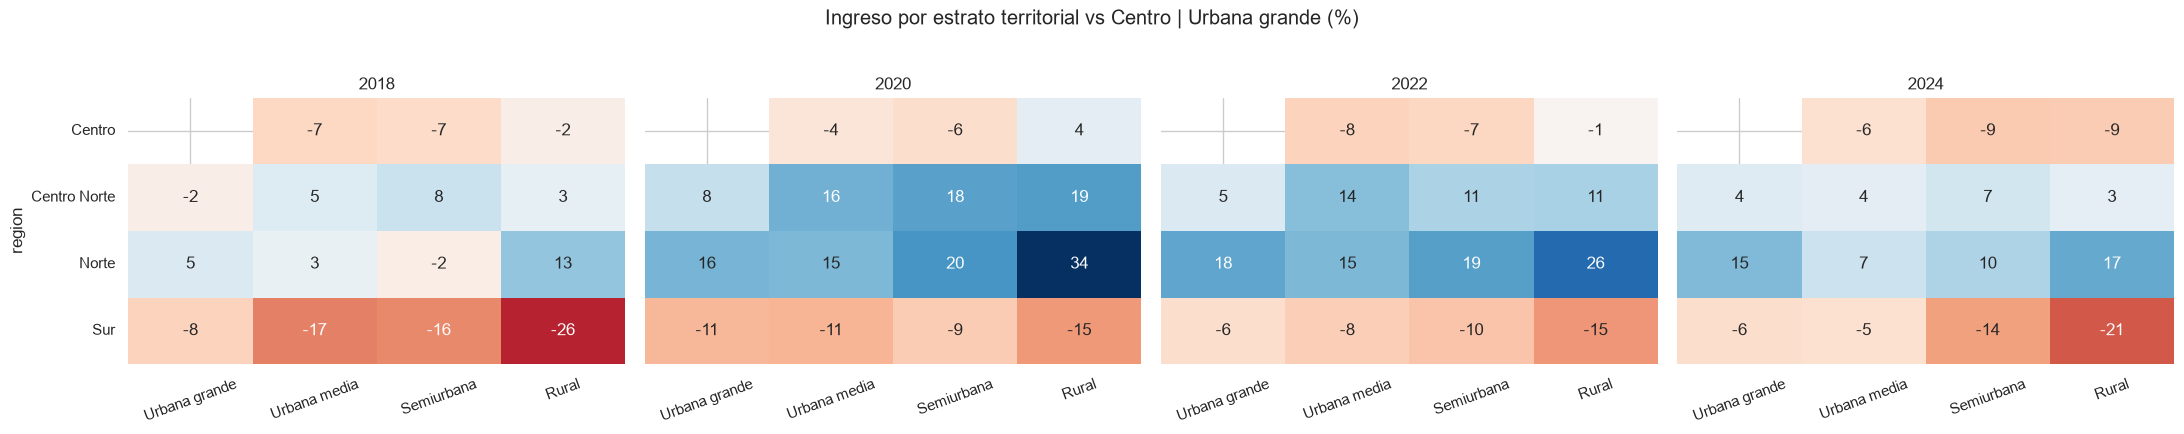

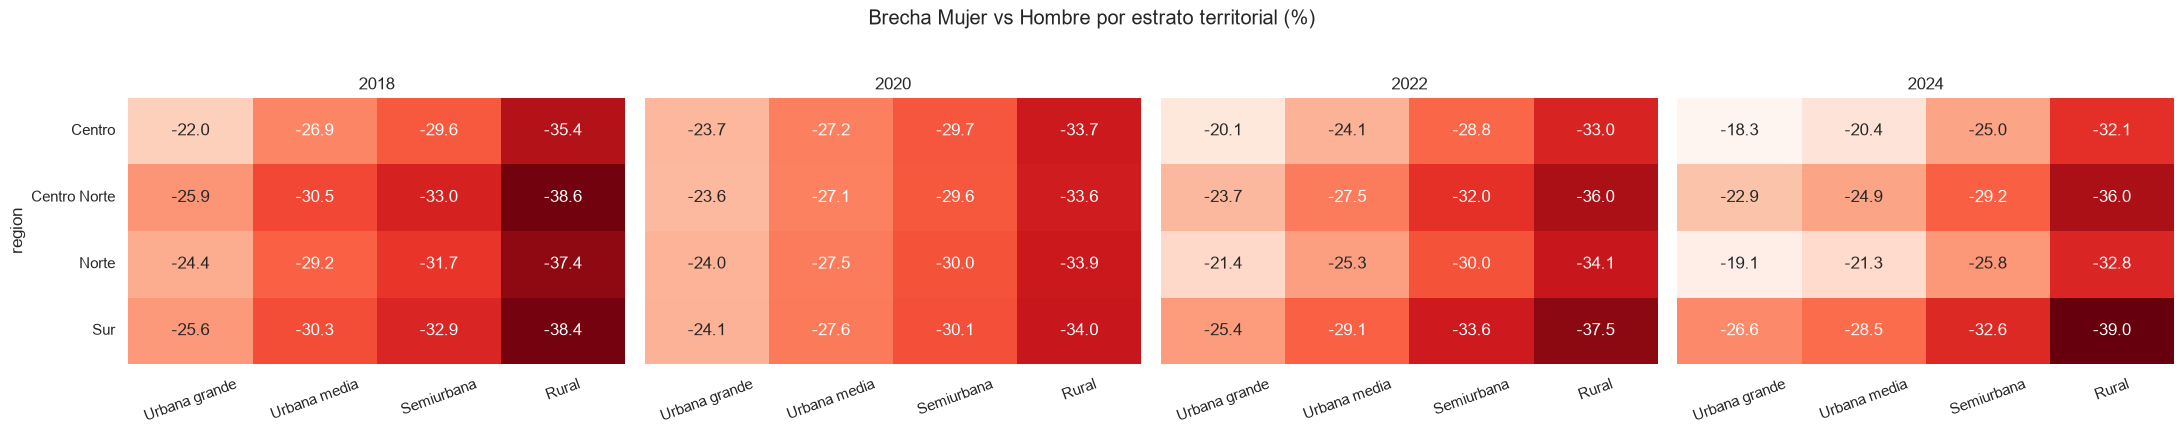

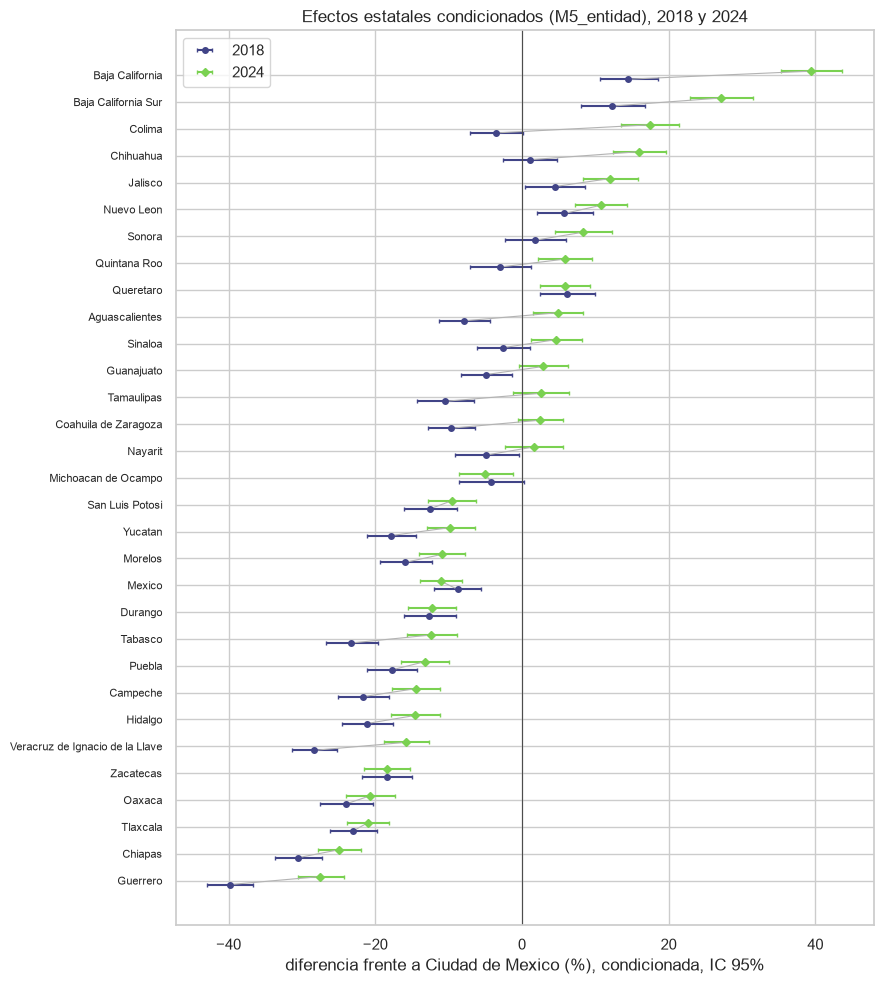

anio,2018,2020,2022,2024
entidad,,,,
Baja California,14.1,36.0,42.8,39.0
Baja California Sur,11.9,14.2,31.7,26.7
Colima,-3.6,18.5,12.4,17.1
Chihuahua,0.9,21.0,21.4,15.8
Jalisco,4.2,28.4,17.6,11.9
Nuevo Leon,5.5,21.1,14.0,10.6
Sonora,1.5,10.6,10.1,8.2
Quintana Roo,-3.2,-13.8,4.0,5.7
Queretaro,5.9,13.5,9.3,5.7


In [10]:
REGIONES = CATEGORIAS["region_banxico"]
LOCALIDADES = ["Urbana grande (100,000+)", "Urbana media (15,000-99,999)", "Semiurbana (2,500-14,999)", "Rural (<2,500)"]
filas_estrato, filas_genero = [], []
for anio in ANIOS:
    modelo, d = modelos[(anio, "M5_final")], datos[anio]
    ref = medias_diseno(contrafactual(d, region_banxico=REFERENCIAS["region_banxico"],
                                      tam_loc_grupo=REFERENCIAS["tam_loc_grupo"]), modelo)
    for region in REGIONES:
        for localidad in LOCALIDADES:
            celda = contrafactual(d, region_banxico=region, tam_loc_grupo=localidad)
            if (region, localidad) != (REFERENCIAS["region_banxico"], REFERENCIAS["tam_loc_grupo"]):
                filas_estrato.append({"anio": anio, "region": region, "localidad": localidad,
                                      **contraste(modelo, medias_diseno(celda, modelo), ref)})
            filas_genero.append({"anio": anio, "region": region, "localidad": localidad,
                                 **contraste(modelo, medias_diseno(contrafactual(celda, sexo_desc="Mujer"), modelo),
                                             medias_diseno(contrafactual(celda, sexo_desc="Hombre"), modelo))})
estratos_territoriales = pd.DataFrame(filas_estrato)
brecha_genero_territorio = pd.DataFrame(filas_genero)

for tabla, nombre, titulo, cmap in [
        (estratos_territoriales, "estratos_territoriales", "Ingreso por estrato territorial vs Centro | Urbana grande (%)", "RdBu"),
        (brecha_genero_territorio, "brecha_genero_territorio", "Brecha Mujer vs Hombre por estrato territorial (%)", "Reds_r")]:
    fig, ejes = plt.subplots(1, len(ANIOS), figsize=(22, 4.2))
    valores = tabla.ame_pct
    for ax, anio in zip(ejes, ANIOS):
        matriz = (tabla.loc[tabla.anio.eq(anio)].pivot(index="region", columns="localidad", values="ame_pct")
                  .reindex(index=REGIONES, columns=LOCALIDADES))
        if cmap == "RdBu":
            limite = np.nanmax(np.abs(valores))
            sns.heatmap(matriz, annot=True, fmt=".0f", cmap=cmap, norm=TwoSlopeNorm(0, -limite, limite), ax=ax, cbar=False)
        else:
            sns.heatmap(matriz, annot=True, fmt=".1f", cmap=cmap, vmin=valores.min(), vmax=valores.max(), ax=ax, cbar=False)
        ax.set_title(str(anio))
        ax.set_xticklabels([l.split(" (")[0] for l in LOCALIDADES], rotation=20)
        ax.set_xlabel("")
        if anio == ANIOS[0]:
            ax.set_yticklabels(REGIONES, rotation=0)
            ax.set_ylabel("region")
        else:
            ax.set_yticklabels([])
            ax.set_ylabel("")
    fig.suptitle(titulo, y=1.03)
    fig.tight_layout()
    mostrar_figura(fig, nombre)


def contraccion_empirica_bayes(theta, varianza):
    w = 1 / varianza
    mu = np.sum(w * theta) / np.sum(w)
    Q = np.sum(w * (theta - mu) ** 2)
    tau2 = max(0.0, (Q - (len(theta) - 1)) / (np.sum(w) - np.sum(w ** 2) / np.sum(w)))
    return mu + tau2 / (tau2 + varianza) * (theta - mu)


filas = []
for anio in ANIOS:
    m = modelos[(anio, "M5_entidad")]
    indices = [i for i, c in enumerate(m["columnas"]) if c.startswith("entidad[")]
    theta = m["beta"][indices]
    varianza = np.diag(m["V"])[indices]
    eb = contraccion_empirica_bayes(theta, varianza)
    for i, t, v, e in zip(indices, theta, varianza, eb):
        se = np.sqrt(v)
        filas.append({"anio": anio, "entidad": m["columnas"][i][8:-1], "ame_log": t, "error_estandar": se,
                      "ame_pct": pct(t), "ic_inferior_pct": pct(t - z_critico * se), "ic_superior_pct": pct(t + z_critico * se),
                      "eb_pct": pct(e), "p_value": 2 * norm.sf(abs(t / se))})
efectos_estatales = pd.DataFrame(filas)
orden = efectos_estatales.loc[efectos_estatales.anio.eq(ANIO_FINAL)].sort_values("eb_pct").entidad.tolist()
fig, ax = plt.subplots(figsize=(9, 10))
y = {e: i for i, e in enumerate(orden)}
for anio, marcador in [(ANIO_INICIAL, "o"), (ANIO_FINAL, "D")]:
    sub = efectos_estatales.loc[efectos_estatales.anio.eq(anio)]
    ax.errorbar(sub.ame_pct, sub.entidad.map(y) + (0.15 if anio == ANIO_FINAL else -0.15),
                xerr=[sub.ame_pct - sub.ic_inferior_pct, sub.ic_superior_pct - sub.ame_pct],
                fmt=marcador, ms=4, capsize=1.5, color=COLORES_ANIO[anio], label=str(anio))
for entidad in orden:
    sub = efectos_estatales.loc[efectos_estatales.entidad.eq(entidad)].set_index("anio")
    ax.plot([sub.loc[ANIO_INICIAL, "ame_pct"], sub.loc[ANIO_FINAL, "ame_pct"]], [y[entidad] - 0.15, y[entidad] + 0.15],
            color="0.7", linewidth=0.8)
ax.axvline(0, color="0.3", linewidth=0.8)
ax.set_yticks(range(len(orden)), orden, fontsize=8)
ax.set_xlabel("diferencia frente a Ciudad de Mexico (%), condicionada, IC 95%")
ax.set_title(f"Efectos estatales condicionados (M5_entidad), {ANIO_INICIAL} y {ANIO_FINAL}")
ax.legend()
fig.tight_layout()
mostrar_figura(fig, "efectos_estatales")
display(efectos_estatales.pivot(index="entidad", columns="anio", values="eb_pct").loc[orden[::-1]].round(1))

## 8. ¿Qué cambió entre 2018 y 2024?

Para cada efecto promedio del modelo final se contrasta el cambio 2018→2024 y la estabilidad en los cuatro años. Los *p-values* se ajustan por Holm dentro de cada familia de contrastes. La figura muestra el cambio en puntos porcentuales de la diferencia en $1+$ingreso.

,etiqueta,pct_2018,pct_2020,pct_2022,pct_2024,cambio_pp_2018_2024,p_cambio_holm,p_estabilidad_holm
15,Escolaridad: Posgrado vs Secundaria,97.729,89.341,89.634,67.978,-29.751,0.000,0.000
27,"Ocupacion: 1 Funcionarios, directores y jefes ...",76.366,79.189,70.795,62.406,-13.960,0.001,0.000
12,Escolaridad: Licenciatura/profesional vs Secun...,41.828,33.247,33.767,28.925,-12.904,0.000,0.000
46,Estrato socioeconomico: Medio alto vs Bajo,21.323,15.862,18.806,9.205,-12.118,0.000,0.000
45,Estrato socioeconomico: Alto vs Bajo,40.789,34.358,34.902,28.969,-11.820,0.000,0.004
...,...,...,...,...,...,...,...,...
48,Region: Centro Norte vs Centro,4.728,14.546,11.718,9.638,4.910,0.000,0.000
50,Region: Sur vs Centro,-14.934,-12.178,-8.016,-8.222,6.712,0.000,0.000
26,Tamano de empresa: No sabe vs 2 a 5 personas,4.083,5.601,8.891,11.394,7.311,0.025,0.072
17,Escolaridad: Sin escolaridad/inicial vs Secund...,-6.662,7.728,0.911,1.621,8.283,1.000,0.126


,etiqueta,pct_2018,pct_2020,pct_2022,pct_2024,cambio_pp_2018_2024,p_cambio_holm
0,Escolaridad: Licenciatura/profesional vs Secun...,64.660,56.520,52.728,43.427,-21.233,0.000
1,Escolaridad: Media superior vs Secundaria,14.370,12.495,12.005,11.169,-3.201,0.013
2,Escolaridad: Normal vs Secundaria,72.339,79.483,66.158,52.156,-20.183,0.115
3,Escolaridad: Posgrado vs Secundaria,171.933,163.695,150.341,110.020,-61.913,0.000
4,Escolaridad: Primaria vs Secundaria,-4.073,-1.715,-3.514,-5.349,-1.276,0.239
5,Escolaridad: Sin escolaridad/inicial vs Secund...,-17.671,-8.760,-13.344,-11.461,6.210,0.111
6,Escolaridad: Tecnica/comercial vs Secundaria,22.163,19.752,20.634,12.578,-9.584,0.001


,region,localidad,pct_2018,pct_2020,pct_2022,pct_2024,cambio_pp_2018_2024,z_cambio,p_cambio,wald_estabilidad,p_estabilidad,p_cambio_holm,p_estabilidad_holm,cambio_significativo_holm
0,Centro,"Urbana grande (100,000+)",-22.042,-23.709,-20.104,-18.281,3.761,2.771,0.006,18.301,0.000,0.056,0.005,False
1,Centro,"Urbana media (15,000-99,999)",-26.941,-27.237,-24.083,-20.437,6.504,3.799,0.000,21.203,0.000,0.002,0.001,True
2,Centro,"Semiurbana (2,500-14,999)",-29.601,-29.744,-28.846,-24.989,4.613,2.713,0.007,11.147,0.011,0.060,0.077,False
3,Centro,"Rural (<2,500)",-35.419,-33.668,-32.996,-32.117,3.302,2.656,0.008,7.413,0.060,0.063,0.332,False
4,Centro Norte,"Urbana grande (100,000+)",-25.857,-23.594,-23.688,-22.906,2.951,2.439,0.015,6.218,0.101,0.103,0.406,False
5,Centro Norte,"Urbana media (15,000-99,999)",-30.516,-27.127,-27.488,-24.940,5.576,3.496,0.000,12.279,0.006,0.006,0.058,True
6,Centro Norte,"Semiurbana (2,500-14,999)",-33.046,-29.638,-32.037,-29.234,3.812,2.324,0.020,7.589,0.055,0.121,0.332,False
7,Centro Norte,"Rural (<2,500)",-38.579,-33.568,-36.001,-35.959,2.620,2.131,0.033,14.501,0.002,0.165,0.025,False
8,Norte,"Urbana grande (100,000+)",-24.413,-23.951,-21.361,-19.120,5.293,4.201,0.000,24.026,0.000,0.000,0.000,True
9,Norte,"Urbana media (15,000-99,999)",-29.162,-27.467,-25.277,-21.254,7.909,4.463,0.000,23.075,0.000,0.000,0.001,True


,familia,contrastes,cambios_significativos_holm
0,efectos promedio M5,61,16
1,escolaridad total M3,7,4
2,estratos territoriales,15,6
3,brecha de genero por territorio,16,6
4,entidades,31,13


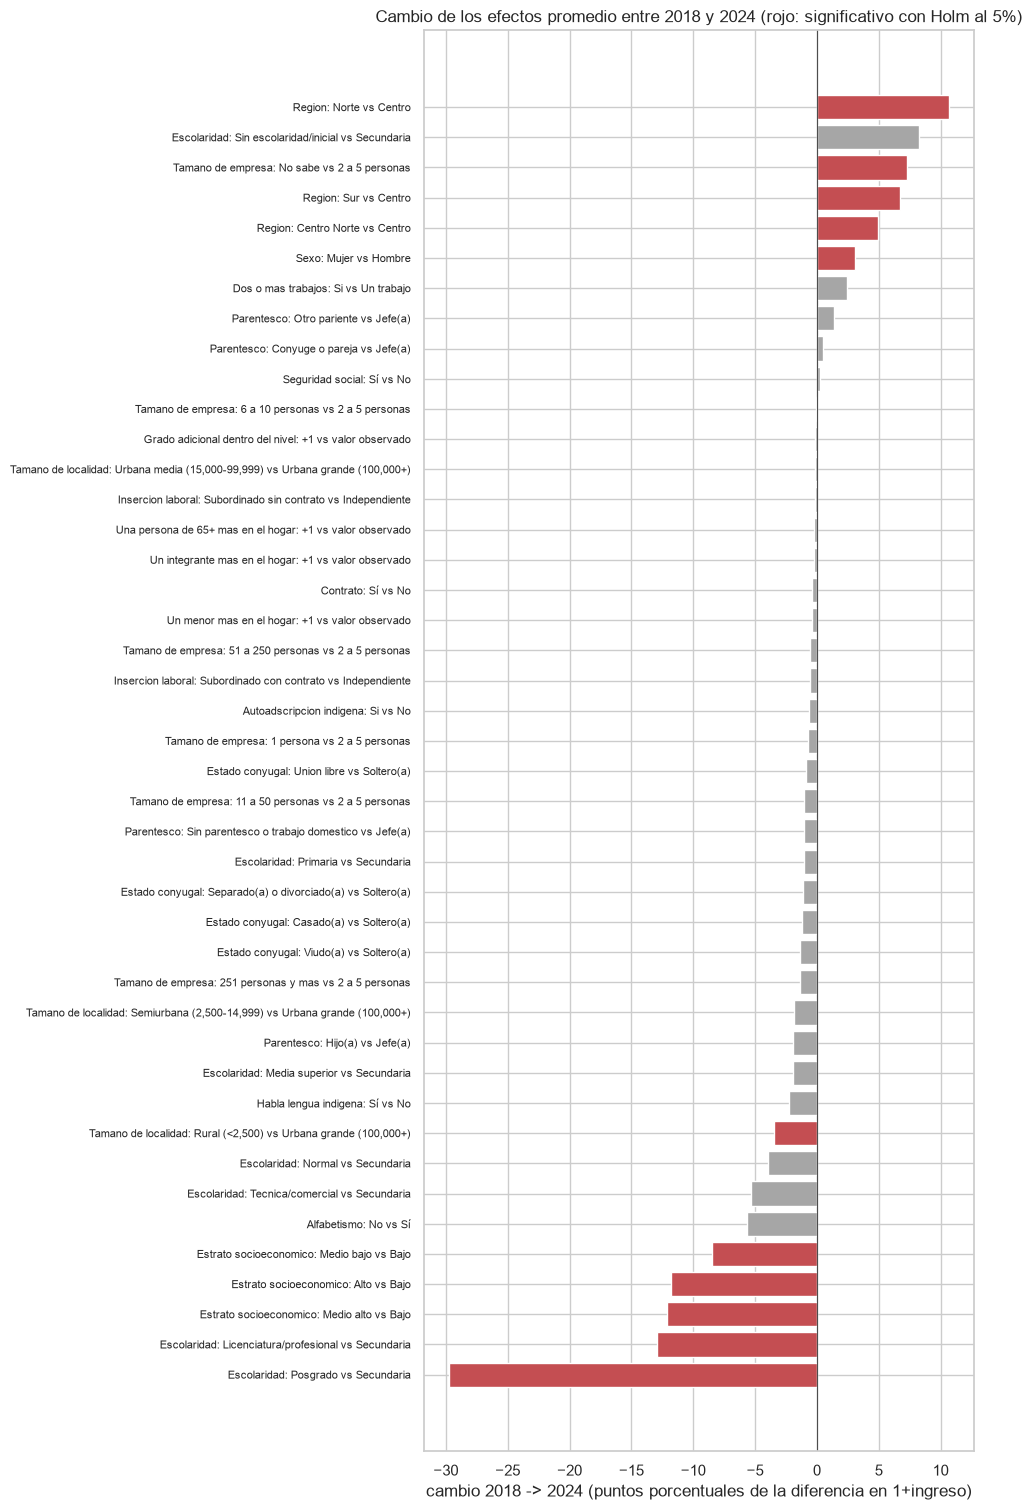

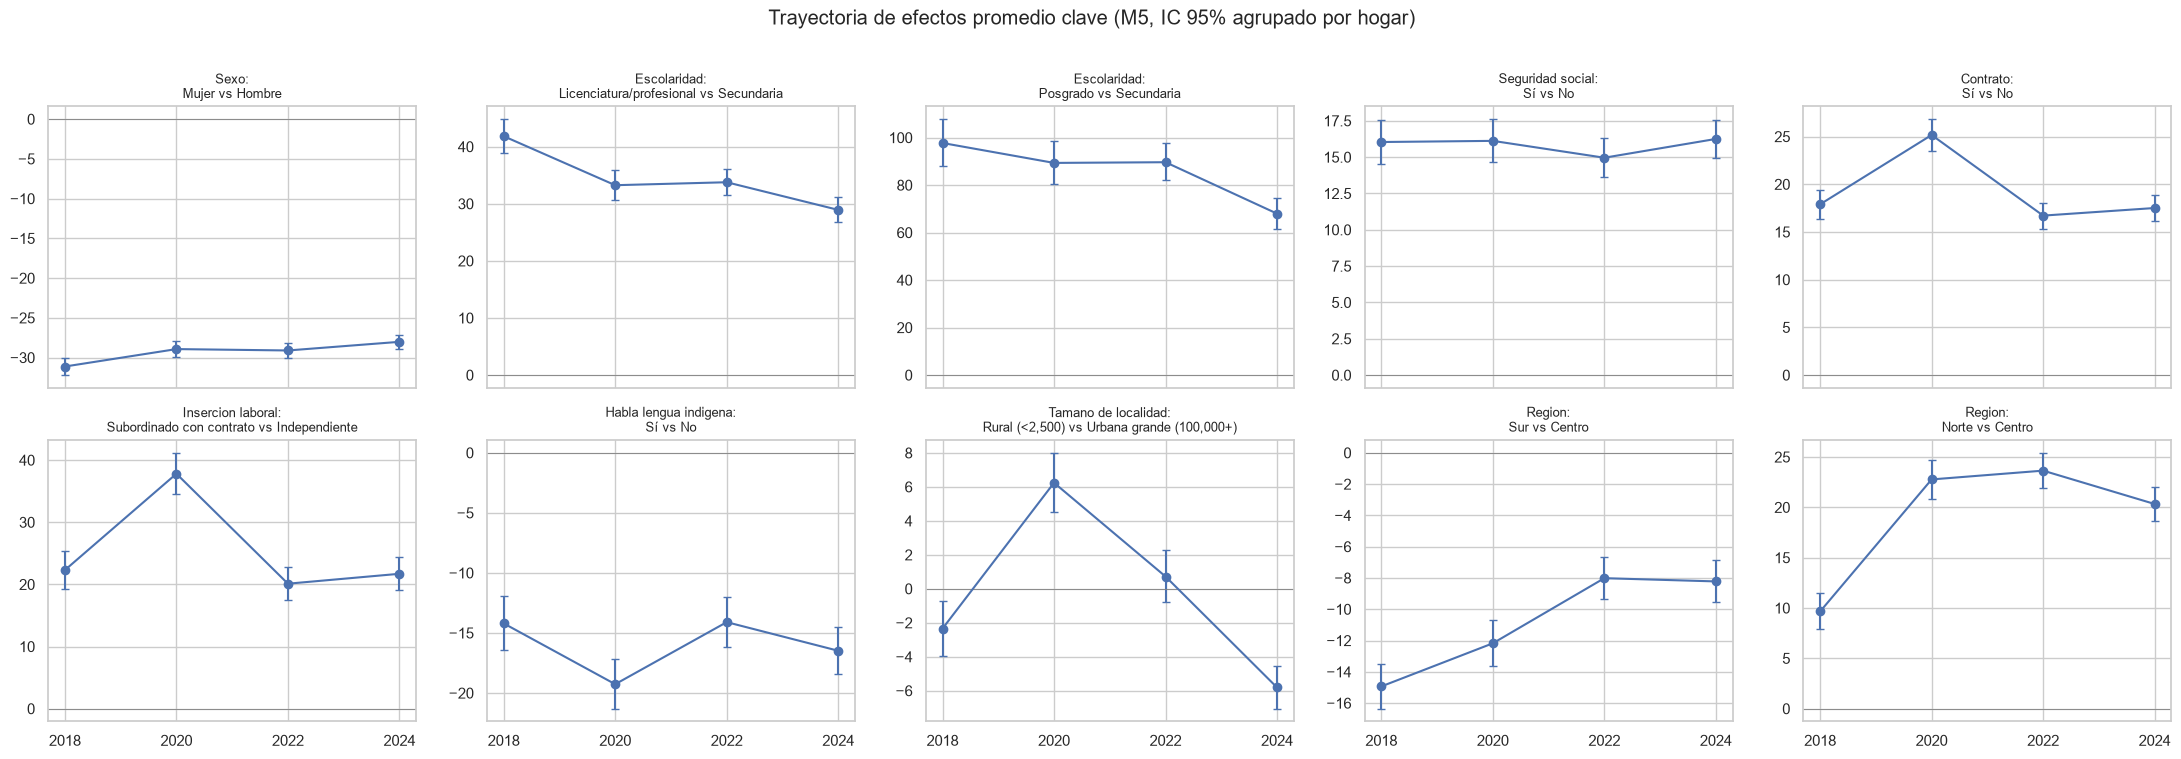

In [11]:
def cambios_temporales(tabla, llaves):
    filas = []
    for clave, grupo in tabla.groupby(llaves, sort=False):
        g = grupo.set_index("anio")
        if not set(ANIOS) <= set(g.index):
            continue
        a, v = g.loc[ANIOS, "ame_log"].to_numpy(), g.loc[ANIOS, "error_estandar"].to_numpy() ** 2
        media = np.sum(a / v) / np.sum(1 / v)
        W = float(np.sum((a - media) ** 2 / v))
        z = (g.loc[ANIO_FINAL, "ame_log"] - g.loc[ANIO_INICIAL, "ame_log"]) / np.sqrt(
            g.loc[ANIO_FINAL, "error_estandar"] ** 2 + g.loc[ANIO_INICIAL, "error_estandar"] ** 2)
        fila = dict(zip(llaves, clave if isinstance(clave, tuple) else (clave,)))
        fila.update({f"pct_{t}": g.loc[t, "ame_pct"] for t in ANIOS})
        fila.update({"cambio_pp_2018_2024": g.loc[ANIO_FINAL, "ame_pct"] - g.loc[ANIO_INICIAL, "ame_pct"],
                     "z_cambio": float(z), "p_cambio": float(2 * norm.sf(abs(z))),
                     "wald_estabilidad": W, "p_estabilidad": float(chi2.sf(W, len(ANIOS) - 1))})
        filas.append(fila)
    resultado = pd.DataFrame(filas)
    resultado["p_cambio_holm"] = multipletests(resultado.p_cambio, method="holm")[1]
    resultado["p_estabilidad_holm"] = multipletests(resultado.p_estabilidad, method="holm")[1]
    resultado["cambio_significativo_holm"] = resultado.p_cambio_holm < ALFA
    return resultado


cambios_efectos = cambios_temporales(efectos_promedio.loc[efectos_promedio.modelo.eq("M5_final")], ["etiqueta"])
cambios_educacion_total = cambios_temporales(efectos_promedio.loc[efectos_promedio.modelo.eq("M3_variables_excluidas")], ["etiqueta"])
cambios_estratos = cambios_temporales(estratos_territoriales, ["region", "localidad"])
cambios_genero_territorio = cambios_temporales(brecha_genero_territorio, ["region", "localidad"])
cambios_estatales = cambios_temporales(efectos_estatales, ["entidad"])
display(cambios_efectos.sort_values("cambio_pp_2018_2024")[["etiqueta"] + [f"pct_{t}" for t in ANIOS]
        + ["cambio_pp_2018_2024", "p_cambio_holm", "p_estabilidad_holm"]].round(3))
display(cambios_educacion_total[["etiqueta"] + [f"pct_{t}" for t in ANIOS] + ["cambio_pp_2018_2024", "p_cambio_holm"]].round(3))
display(cambios_genero_territorio.round(3))
display(pd.DataFrame([{"familia": n, "contrastes": len(t), "cambios_significativos_holm": int(t.cambio_significativo_holm.sum())}
                      for n, t in [("efectos promedio M5", cambios_efectos), ("escolaridad total M3", cambios_educacion_total),
                                   ("estratos territoriales", cambios_estratos), ("brecha de genero por territorio", cambios_genero_territorio),
                                   ("entidades", cambios_estatales)]]))

clave = cambios_efectos.loc[~cambios_efectos.etiqueta.str.startswith(("Ocupacion", "Sector"))].sort_values("cambio_pp_2018_2024")
fig, ax = plt.subplots(figsize=(10, 0.32 * len(clave) + 1.5))
colores = np.where(clave.cambio_significativo_holm, "#c44e52", "0.65")
ax.barh(range(len(clave)), clave.cambio_pp_2018_2024, color=colores)
ax.axvline(0, color="0.3", linewidth=0.8)
ax.set_yticks(range(len(clave)), clave.etiqueta, fontsize=8)
ax.set_xlabel("cambio 2018 -> 2024 (puntos porcentuales de la diferencia en 1+ingreso)")
ax.set_title("Cambio de los efectos promedio entre 2018 y 2024 (rojo: significativo con Holm al 5%)")
fig.tight_layout()
mostrar_figura(fig, "cambios_2018_2024")

TRAYECTORIAS = ["Sexo: Mujer vs Hombre", "Escolaridad: Licenciatura/profesional vs Secundaria",
                "Escolaridad: Posgrado vs Secundaria", "Seguridad social: Sí vs No", "Contrato: Sí vs No",
                "Insercion laboral: Subordinado con contrato vs Independiente", "Habla lengua indigena: Sí vs No",
                "Tamano de localidad: Rural (<2,500) vs Urbana grande (100,000+)",
                "Region: Sur vs Centro", "Region: Norte vs Centro"]
sub = efectos_promedio.loc[efectos_promedio.modelo.eq("M5_final") & efectos_promedio.etiqueta.isin(TRAYECTORIAS)]
fig, ejes = plt.subplots(2, 5, figsize=(22, 7.5), sharex=True)
for ax, etiqueta in zip(ejes.ravel(), TRAYECTORIAS):
    s = sub.loc[sub.etiqueta.eq(etiqueta)].sort_values("anio")
    ax.errorbar(s.anio, s.ame_pct, yerr=[s.ame_pct - s.ic_inferior_pct, s.ic_superior_pct - s.ame_pct],
                fmt="o-", capsize=3, color="#4c72b0")
    ax.axhline(0, color="0.5", linewidth=0.6)
    ax.set_title(etiqueta.replace(": ", ":\n"), fontsize=9)
    ax.set_xticks(ANIOS)
fig.suptitle("Trayectoria de efectos promedio clave (M5, IC 95% agrupado por hogar)", y=1.01)
fig.tight_layout()
mostrar_figura(fig, "trayectorias_efectos_clave")

## 9. Exportación

Las tablas se guardan en `outputs/interpretacion_modelo_final/` y las figuras, además, en `reports/figures/interpretacion_modelo_final/` para el reporte narrativo. Todas provienen de esta ejecución.

In [12]:
tablas_salida = {
    "ajuste_modelos": ajuste_modelos, "efectos_promedio": efectos_promedio, "perfiles_edad": perfiles_edad,
    "perfiles_horas": perfiles_horas, "estratos_territoriales": estratos_territoriales,
    "brecha_genero_territorio": brecha_genero_territorio, "efectos_estatales": efectos_estatales,
    "cambios_efectos": cambios_efectos, "cambios_educacion_total": cambios_educacion_total,
    "cambios_estratos": cambios_estratos, "cambios_genero_territorio": cambios_genero_territorio,
    "cambios_estatales": cambios_estatales,
}
manifest = {
    "estado": "ejecutado_pendiente_revision_humana",
    "fecha_ejecucion": INICIO_EJECUCION.isoformat(timespec="seconds"),
    "unidad_analisis": "persona", "target": LOG_TARGET, "target_monetario": "nominal trimestral; sin deflactar",
    "insumo": str(MANIFEST_15.relative_to(PROJECT_ROOT)), "fecha_insumo_15": manifest_15["fecha_ejecucion"],
    "modelo_principal": "M5_final", "modelos_complementarios": ["M3_variables_excluidas", "M5_entidad"],
    "bloques_interaccion": BLOQUES,
    "efecto_promedio": "AME en log: (media x escenario - media x referencia)' beta; IC exacto con covarianza cluster hogar",
    "comparacion_temporal": "z de diferencia con muestras independientes; Wald chi2(3) de estabilidad; Holm por familia",
    "versiones": {"python": sys.version.split()[0], "pandas": pd.__version__, "numpy": np.__version__,
                  "statsmodels": statsmodels.__version__},
}
if EXPORTAR_RESULTADOS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    FIGURAS_REPORTE_DIR.mkdir(parents=True, exist_ok=True)
    for nombre, tabla in tablas_salida.items():
        tabla.to_csv(OUTPUT_DIR / f"{nombre}.csv", index=False)
    for nombre, figura in FIGURAS.items():
        figura.savefig(FIGURAS_REPORTE_DIR / f"{nombre}.png", dpi=110, bbox_inches="tight")
    (OUTPUT_DIR / "manifest_interpretacion.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2),
                                                              encoding="utf-8")
display(pd.DataFrame([{"exportacion": "realizada" if EXPORTAR_RESULTADOS else "desactivada",
                       "tablas": len(tablas_salida), "figuras": len(FIGURAS)}]))

,exportacion,tablas,figuras
0,realizada,12,10
